# 1.3 Exploración P2 (Versión Depurada): Sin Ruido de Madrugada, Variables Clave y Auditoría Anti-Leakage

En esta versión refinamos el pipeline de la **Pregunta 2 (Clasificación Ternaria)** aplicando tres mejoras estructurales:

1. **Limpieza del ruido de madrugada (`00:00` y `03:00` h):**
   - Como se sustentó en el notebook `1.0`, el sistema MiBici no opera de `00:00` a `06:00` h. Incluir esos 2 bloques diarios metía ~280,000 filas artificiales en `0: Normal` y hacía que a las `06:00 AM` el `lag_1` mirara las `03:00 AM` (siempre en cero) en lugar del cierre de la noche anterior (`21:00` h).
   - Además, acotamos `flujo_por_bloque` hasta `FECHA_FIN` (`2026-09-30`) para que viajes nocturnos que terminaron pasadas las `00:00` del 1 de octubre no generen bloques vacíos en un mes fuera del rango.
2. **Podado de variables redundantes/ruidosas (De 36 a ~20 columnas efectivas):**
   - Eliminamos la duplicidad entre conteos brutos y ratios (nos quedamos únicamente con los **ratios divididos por `capacidad`**).
   - Reemplazamos las 7 columnas de `dia_semana` y `festivo` por una sola bandera `es_fin_de_semana`.
3. **Auditoría estricta contra Fuga de Datos (*Data Leakage*):**
   - Todos los rezagos usan `.shift()` de al menos 1 bloque hacia el pasado.
   - El perfil `Estación × Hora` y los transformadores (`Yeo-Johnson`, `RobustScaler`, `OHE`) se ajustan **exclusivamente sobre `Train` (`bloque < 2026-06-01`)**.

## 1. Importaciones y Parámetros de Experimentación

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, RobustScaler

from mi_bici.dataset import load_processed_stations, load_processed_travels
from mi_bici.features import flujo_por_bloque
from mi_bici.config import (
    BLOQUE_HORAS,
    CORTE_PRUEBA,
    CORTE_VALIDACION,
    FECHA_FIN,
    SEMILLA,
)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.autolayout"] = True

# =============================================================================
# PARÁMETROS PARA EXPERIMENTAR EN ESTE NOTEBOOK
# =============================================================================
UMBRAL_EXPERIMENTO = 0.40  # Fracción de la capacidad para definir Saturado (+40%) y Vaciado (-40%)
K_VECINOS = 3              # Número de estaciones vecinas más cercanas
HORA_APERTURA = 6          # Filtrar bloques de madrugada (00:00 y 03:00) donde MiBici está cerrado
OBJETIVO_TERNARIO = "estado_estacion"

print(f"Configuración activa -> Umbral: {UMBRAL_EXPERIMENTO:.0%} | Vecinos: K={K_VECINOS} | Horas activas: >= {HORA_APERTURA:02d}:00")
print(f"Cortes oficiales     -> Validación: {CORTE_VALIDACION} | Prueba: {CORTE_PRUEBA}")

2026-10-26 19:17:51.324 | INFO     | mi_bici.config:<module>:12 - PROJ_ROOT path is: /home/miguel/Maestria/Trimestre4/mlops/proyecto-integrador


Configuración activa -> Umbral: 40% | Vecinos: K=3 | Horas activas: >= 06:00
Cortes oficiales     -> Validación: 2026-06-01 | Prueba: 2026-08-01


## 2. Carga de Parquets, Limpieza de Madrugada (`hora >= 6`) y Objetivo Ternario

Corregimos los dos detalles detectados en `flujo_por_bloque`:
1. Descartamos cualquier bloque que se haya pasado al 1 de octubre (`bloque <= 2026-09-30 21:00:00`) por viajes que terminaron después de medianoche.
2. Filtramos únicamente los **6 bloques operativos del día (`06:00`, `09:00`, `12:00`, `15:00`, `18:00`, `21:00`)** eliminando el ruido de las `00:00` y `03:00`.
3. Ordenamos explícitamente por `["estacion_id", "bloque"]` después del `merge`.

In [2]:
# 1. Carga de archivos Parquet procesados
viajes = load_processed_travels()
estaciones = load_processed_stations()

# 2. Construcción del flujo base por bloque de 3 horas
df_crudo = flujo_por_bloque(viajes, estaciones, horas=BLOQUE_HORAS)
df_crudo = df_crudo[df_crudo["capacidad"] > 0].copy()
filas_antes = len(df_crudo)

# 3. Limpieza de fecha límite (evitar bloques fantasma en octubre) y de horas de madrugada (< 06:00 AM)
fecha_limite = pd.Timestamp(FECHA_FIN) + pd.Timedelta(hours=23, minutes=59)
df = df_crudo[
    (df_crudo["bloque"] <= fecha_limite) &
    (df_crudo["bloque"].dt.hour >= HORA_APERTURA)
].copy()

print(f"Filas totales antes de limpiar madrugada: {filas_antes:,}")
print(f"Filas operativas (06:00 a 21:00 h):       {len(df):,} (se eliminaron {filas_antes - len(df):,} bloques sin servicio)")

# 4. Join con coordenadas de estaciones.parquet y ordenamiento cronológico estricto
df = df.merge(
    estaciones[["estacion_id", "latitud", "longitud"]],
    on="estacion_id",
    how="left",
)
df = df.sort_values(["estacion_id", "bloque"]).reset_index(drop=True)

# 5. Creación de la etiqueta ternaria según UMBRAL_EXPERIMENTO
limite_bicis = UMBRAL_EXPERIMENTO * df["capacidad"]
condiciones = [
    df["flujo_neto"] >= limite_bicis,   # 1: Saturado (exceso de llegadas)
    df["flujo_neto"] <= -limite_bicis,  # 2: Riesgo Vaciado (exceso de salidas)
]
df[OBJETIVO_TERNARIO] = np.select(condiciones, [1, 2], default=0)

resumen_clases = pd.DataFrame({
    "Bloques Operativos": df[OBJETIVO_TERNARIO].value_counts().sort_index(),
    "Porcentaje (%)": (df[OBJETIVO_TERNARIO].value_counts(normalize=True).sort_index() * 100).round(2),
})
resumen_clases.index = ["0: Flujo Normal", "1: Saturado (+llegadas)", "2: Riesgo Vaciado (-salidas)"]
print("\n--- Distribución del Objetivo Ternario (Solo Horas Operativas) ---")
display(resumen_clases)

Filas totales antes de limpiar madrugada: 1,149,261
Filas operativas (06:00 a 21:00 h):       862,024 (se eliminaron 287,237 bloques sin servicio)

--- Distribución del Objetivo Ternario (Solo Horas Operativas) ---


,Bloques Operativos,Porcentaje (%)
0: Flujo Normal,807576,93.68
1: Saturado (+llegadas),28647,3.32
2: Riesgo Vaciado (-salidas),25801,2.99


## 3. Cálculo Espacial de Estaciones Vecinas (`estaciones.parquet`)

Las coordenadas físicas (`latitud`, `longitud`) provienen del catálogo estático de estaciones, por lo que encontrar los $K=3$ vecinos más cercanos con distancia Haversine no involucra ninguna variable temporal futura.

In [3]:
RADIO_TIERRA_METROS = 6_371_000

est_activas = (
    estaciones[estaciones["estacion_id"].isin(df["estacion_id"].unique())]
    .copy()
    .reset_index(drop=True)
)

coords_rad = np.radians(est_activas[["latitud", "longitud"]].to_numpy())
buscador_vecinos = NearestNeighbors(n_neighbors=K_VECINOS + 1, metric="haversine")
buscador_vecinos.fit(coords_rad)
distancias_rad, indices_vecinos = buscador_vecinos.kneighbors(coords_rad)

pares_vecinos = []
ids_estaciones = est_activas["estacion_id"].to_numpy()

for idx_origen, id_origen in enumerate(ids_estaciones):
    for orden in range(1, K_VECINOS + 1):
        idx_vec = indices_vecinos[idx_origen, orden]
        pares_vecinos.append({
            "estacion_id": id_origen,
            "vecino_id": ids_estaciones[idx_vec],
            "orden_vecino": orden,
            "distancia_m": round(distancias_rad[idx_origen, orden] * RADIO_TIERRA_METROS, 1),
        })

df_vecinos = pd.DataFrame(pares_vecinos)
print(f"Grafo espacial listo: {len(est_activas)} estaciones conectadas con sus {K_VECINOS} vecinos más cercanos.")

Grafo espacial listo: 469 estaciones conectadas con sus 3 vecinos más cercanos.


## 4. Construcción de los Features de NYC y Barcelona (Rezagos, Acumulado y Vecinos)

En este punto construimos desde cero las variables explicativas cuidando que **todas usen exclusivamente información de bloques anteriores ($t-1$ o previos)** para evitar cualquier fuga de información (*data leakage*).

### ¿Qué cambia al haber quitado las horas muertas (`00:00` y `03:00`)?
* Ahora cada día tiene exactamente **6 bloques operativos** (`06:00`, `09:00`, `12:00`, `15:00`, `18:00`, `21:00`).
* **Ventaja en el `lag_1` de las `06:00 AM`:** Cuando queremos predecir el primer bloque de la mañana (`06:00 a 09:00`), un desplazamiento hacia atrás (`.shift(1)`) ya no apunta a las `03:00 AM` (donde siempre había 0 viajes), sino al bloque de las **`21:00 a 00:00` de la noche anterior**, dándole al modelo información real de cómo cerró la estación.
* **Rezagos semanales exactos:** Como hay 6 bloques por día y 7 días por semana, **1 semana exacta hacia atrás a la misma hora son $7 \times 6 = 42$ filas** (`.shift(42)`).

---

### Diccionario de Variables Generadas en este Bloque

| Variable | Fórmula Matemática | Qué significa físicamente | Por qué se incluye (Justificación) |
| :--- | :--- | :--- | :--- |
| **`hora`** | `bloque.dt.hour` ($6, 9, 12, 15, 18, 21$) | Hora de inicio del bloque de 3h que queremos predecir. | El sentido de los viajes se invierte entre la mañana (vaciado residencial / llenado laboral) y la tarde. |
| **`es_fin_de_semana`** | `1` si Sábado/Domingo, `0` si Lun–Vie | Indica si el bloque cae en fin de semana. | Resume en 1 sola columna el cambio entre movilidad de oficina/escuela y movilidad recreativa, evitando meter 7 columnas ruidosas de `dia_semana`. |
| **`ratio_flujo_cap_lag1`** | $\frac{\text{flujo\_neto}_{t-1}}{\text{capacidad}}$ | Fracción de la capacidad de la estación que se llenó ($+$) o se vació ($-$) en el bloque inmediato anterior ($t-1$). | Pone a estaciones chicas (12 anclajes) y grandes (40 anclajes) en la misma escala del umbral (`0.40`). |
| **`ratio_salidas_cap_lag1`** | $\frac{\text{salidas}_{t-1}}{\text{capacidad}}$ | Qué proporción de la capacidad salió en las últimas 3 horas. | Distingue una estación sin uso (`0 salidas, 0 llegadas`) de una estación con altísima rotación en equilibrio (`15 salidas, 15 llegadas`). |
| **`ratio_llegadas_cap_lag1`** | $\frac{\text{llegadas}_{t-1}}{\text{capacidad}}$ | Qué proporción de la capacidad llegó en las últimas 3 horas. | Una racha alta de llegadas recientes anticipa que los anclajes se están agotando (`1: Saturado`). |
| **`ratio_flujo_media_4sem`** *(NYC/BCN #1)* | $\frac{1}{4}\sum_{k=1}^{4} \left(\frac{\text{flujo\_neto}_{t - 42k}}{\text{capacidad}}\right)$ | Promedio del flujo relativo que tuvo esta estación hace **1, 2, 3 y 4 semanas** exactamente el mismo día y a la misma hora. | Mirar solo hace 1 semana es riesgoso si ese día llovió o fue festivo. Promediar 4 semanas captura la rutina real y suaviza anomalías. |
| **`estado_semana_anterior`** | $\text{estado\_estacion}_{t - 42}$ (`0`, `1` o `2`) | En qué estado (`Normal`, `Saturado` o `Vaciado`) estuvo esta estación hace exactamente 7 días a esta misma hora. | Conecta directamente con la regla del Baseline semanal del proyecto. |
| **`ratio_acumulado_hoy_cap_lag1`** *(NYC/BCN #2)* | $\frac{\sum_{\text{desde 06:00 hasta } t-1} \text{flujo\_neto}}{\text{capacidad}}$ | Balance neto acumulado por la estación **desde que abrió a las 06:00 AM de hoy** hasta antes de que inicie el bloque actual. | **Inventario virtual:** Como MiBici no publica cuántas bicis hay estacionadas en cada instante, sumar cuánto se ha llenado o vaciado desde las 06:00 AM estima qué tan llena llega la estación al bloque actual. |
| **`ratio_flujo_vecinos_lag1`** *(NYC/BCN #3)* | $\frac{1}{K}\sum_{v \in \text{Vecinos}} \text{ratio\_flujo\_cap\_lag1}_v$ | Promedio del flujo relativo que tuvieron las **$K=3$ estaciones más cercanas** (a ~200–300 m) en el bloque anterior ($t-1$). | **Efecto contagio (*spillover*):** Si las estaciones vecinas se vaciaron o saturaron hace 3 horas, los usuarios caminan una cuadra hacia nuestra estación y le transfieren la presión. |

In [ ]:
# =========================================================================
# PASO A: Variables de Calendario (Conocidas de antemano)
# =========================================================================
# Extraemos la hora del bloque (6, 9, 12, 15, 18, 21)
df["hora"] = df["bloque"].dt.hour
# dayofweek en pandas va de 0 (Lunes) a 6 (Domingo). >= 5 identifica Sábado (5) y Domingo (6)
df["es_fin_de_semana"] = (df["bloque"].dt.dayofweek >= 5).astype(int)

# =========================================================================
# PASO B: Rezagos Inmediatos del Bloque Anterior (t - 1) Normalizados
# =========================================================================
# Agrupamos por estacion_id para que .shift(1) jamás mezcle datos de una estación con otra.
# Como df ya está ordenado por [estacion_id, bloque], .shift(1) toma exactamente la fila anterior (hace 3h).
por_estacion = df.groupby("estacion_id")

flujo_lag_1 = por_estacion["flujo_neto"].shift(1)    # Llegadas - Salidas en el bloque t-1
salidas_lag_1 = por_estacion["salidas"].shift(1)     # Total de salidas en el bloque t-1
llegadas_lag_1 = por_estacion["llegadas"].shift(1)   # Total de llegadas en el bloque t-1

# Dividimos entre la capacidad de cada estación para obtener porcentajes comparables
df["ratio_flujo_cap_lag1"] = flujo_lag_1 / df["capacidad"]
df["ratio_salidas_cap_lag1"] = salidas_lag_1 / df["capacidad"]
df["ratio_llegadas_cap_lag1"] = llegadas_lag_1 / df["capacidad"]

# =========================================================================
# PASO C: Feature NYC/BCN #1 — Memoria Semanal de las Últimas 4 Semanas
# =========================================================================
# ¿Cuántas filas hay que retroceder para caer en el mismo día y misma hora de la semana pasada?
# Como quitamos 00:00 y 03:00, quedan (24 - 6) // 3 = 6 bloques por día.
# Por lo tanto, 1 semana exacta son 7 días * 6 bloques = 42 filas hacia atrás.
bloques_operativos_dia = (24 - HORA_APERTURA) // BLOQUE_HORAS  # 6 bloques/día
bloques_por_semana = 7 * bloques_operativos_dia                # 42 bloques/semana

# Calculamos el ratio de flujo en una variable suelta (fuera de df para no contaminar las columnas)
# y aplicamos .shift(42), .shift(84), .shift(126) y .shift(168) equivalentes a 1, 2, 3 y 4 semanas atrás.
ratio_actual_temp = df["flujo_neto"] / df["capacidad"]
lags_semanales = pd.DataFrame({
    f"sem_{sem}": ratio_actual_temp.groupby(df["estacion_id"]).shift(sem * bloques_por_semana)
    for sem in [1, 2, 3, 4]
})

# .mean(axis=1) promedia horizontalmente las 4 semanas pasadas (ignorando NaNs si la estación lleva solo 1 o 2 semanas)
df["ratio_flujo_media_4sem"] = lags_semanales.mean(axis=1)

# También guardamos cuál fue la clase (0, 1 o 2) hace exactamente 1 semana (42 bloques atrás)
df["estado_semana_anterior"] = df.groupby("estacion_id")[OBJETIVO_TERNARIO].shift(bloques_por_semana)

# =========================================================================
# PASO D: Feature NYC/BCN #2 — Inventario Acumulado del Día (desde las 06:00 AM hasta t - 1)
# =========================================================================
# Queremos saber cuántas bicis ha ganado o perdido la estación HOY antes de que empiece el bloque actual:
# - Si estamos en el bloque de las 06:00 AM (apertura), hoy aún no ha transcurrido ningún bloque previo -> vale 0.0.
# - Si estamos a las 09:00 AM -> vale el flujo_lag_1 (que fue el bloque de 06:00 a 09:00).
# - Si estamos a las 12:00 PM -> vale la suma de (06:00 a 09:00) + (09:00 a 12:00), y así sucesivamente.
fecha_dia = df["bloque"].dt.date
flujo_previo_mismo_dia = flujo_lag_1.where(df["hora"] > HORA_APERTURA, 0.0).fillna(0.0)

# Agrupamos por [estacion_id, fecha_dia] y hacemos suma acumulada (.cumsum()) para que se reinicie cada mañana
acumulado_hoy_lag1 = flujo_previo_mismo_dia.groupby([df["estacion_id"], fecha_dia]).cumsum()
df["ratio_acumulado_hoy_cap_lag1"] = acumulado_hoy_lag1 / df["capacidad"]

# =========================================================================
# PASO E: Feature NYC/BCN #3 — Flujo Promedio de los K=3 Vecinos en t - 1
# =========================================================================
# Hacer un merge tradicional de 860,000 filas contra 3 vecinos tardaría mucho y triplicaría la memoria.
# En su lugar usamos un truco matricial con .pivot():
# 1) Creamos una tabla donde las FILAS son las fechas ('bloque') y las COLUMNAS son las 469 estaciones,
#    rellena con 'ratio_flujo_cap_lag1' (lo que pasó hace 3 horas en cada estación).
matriz_ratio_lag1 = df.pivot(index="bloque", columns="estacion_id", values="ratio_flujo_cap_lag1")

# 2) Creamos un diccionario {estacion_id: [id_vecino_1, id_vecino_2, id_vecino_3]} a partir de la Sección 3
mapa_vecinos = df_vecinos.groupby("estacion_id")["vecino_id"].apply(list).to_dict()

# 3) Para cada estación, seleccionamos las 3 columnas de sus vecinos en la matriz y calculamos su promedio (.mean(axis=1))
ratio_vec_dict = {
    est_id: matriz_ratio_lag1[vecinos].mean(axis=1)
    for est_id, vecinos in mapa_vecinos.items()
}

# 4) Convertimos el resultado de vuelta a formato tabla larga (bloque, estacion_id, ratio_flujo_vecinos_lag1) con .stack()
tabla_ratio_vec = pd.DataFrame(ratio_vec_dict)
tabla_ratio_vec.columns.name = "estacion_id"
df_ratio_vec = tabla_ratio_vec.stack().rename("ratio_flujo_vecinos_lag1").reset_index()

# 5) Unimos esa columna a nuestro DataFrame principal
df = df.merge(df_ratio_vec, on=["bloque", "estacion_id"], how="left")
df["ratio_flujo_vecinos_lag1"] = df["ratio_flujo_vecinos_lag1"].fillna(0.0)

# Finalmente descartamos los primeros 7 días de cada estación donde aún no existía 'estado_semana_anterior'
df = df.dropna().reset_index(drop=True)

print(f"Filas operativas listas tras rezagos: {len(df):,}")
print("Verificación en Estación 2: observa cómo a las 06:00 AM el lag_1 ya no es 0, sino el cierre de las 21:00 h previas:")
cols_vista = [
    "estacion_id", "bloque", OBJETIVO_TERNARIO,
    "ratio_flujo_cap_lag1", "ratio_acumulado_hoy_cap_lag1",
    "ratio_flujo_vecinos_lag1", "ratio_flujo_media_4sem",
]
display(df[cols_vista].head(7))

## 5. Partición Temporal, Feature NYC/BCN #4 (`Perfil Estación × Hora`) y Auditoría Anti-Leakage

Las 3 variables más potentes del modelo son el **Perfil Histórico `Estación × Hora`**. A diferencia de los rezagos de la Sección 4, estas variables son agregaciones estadísticas sobre el comportamiento histórico de cada estación, por lo que **deben calcularse DESPUÉS de separar `Train` (`bloque < 2026-06-01`)** para no filtrar información del futuro (`Validación` o `Prueba`).

### Diccionario de Variables Generadas en el Punto 5

| Variable | Fórmula (calculada solo en `Train` con suavizado $m=10$) | Qué significa | Por qué evita Data Leakage |
| :--- | :--- | :--- | :--- |
| **`tasa_saturado_est_hora`** | $\frac{\text{bloques saturados}_{(e, h)} + m \cdot \bar{y}_{\text{sat}}}{n_{(e, h)} + m}$ | Probabilidad histórica de que la estación $e$ a la hora $h$ termine **Saturada (`Clase 1`)**. | Solo cuenta bloques ocurridos antes del `2026-06-01`. Si una estación tuvo pocos días en `Train` ($n$ pequeño), el término $m=10$ la acerca al promedio global $\bar{y}_{\text{sat}}$ para que el árbol no memorice ruido. |
| **`tasa_vaciado_est_hora`** | $\frac{\text{bloques vaciados}_{(e, h)} + m \cdot \bar{y}_{\text{vac}}}{n_{(e, h)} + m}$ | Probabilidad histórica de que la estación $e$ a la hora $h$ termine **Vaciada (`Clase 2`)**. | Permite al modelo distinguir que una estación se vacía a las `06:00 AM` pero nunca a las `18:00 PM`, usando solo historia de entrenamiento. |
| **`ratio_flujo_medio_est_hora`** | $\frac{\sum (\text{flujo\_neto}/\text{cap})_{(e, h)} + m \cdot \bar{r}}{n_{(e, h)} + m}$ | Qué porcentaje de su capacidad suele ganar ($+$) o perder ($-$) en promedio la estación $e$ a la hora $h$. | Resume la vocación neta de la estación en cada turno del día sin tocar `Validación` ni `Prueba`. |

In [5]:
# 1. Máscaras de partición temporal estricta
mask_train = df["bloque"] < CORTE_VALIDACION
mask_val = (df["bloque"] >= CORTE_VALIDACION) & (df["bloque"] < CORTE_PRUEBA)
mask_test = df["bloque"] >= CORTE_PRUEBA

df_train = df.loc[mask_train].copy()

# 2. Cálculo del Perfil Histórico (Estación x Hora) SOLO en Train con Suavizado (m=10)
# El suavizado evita in-sample target leakage en estaciones con pocas observaciones
M_SMOOTH = 10
media_global_sat = (df_train[OBJETIVO_TERNARIO] == 1).mean()
media_global_vac = (df_train[OBJETIVO_TERNARIO] == 2).mean()
media_global_flujo = (df_train["flujo_neto"] / df_train["capacidad"]).mean()

df_train["_es_sat"] = (df_train[OBJETIVO_TERNARIO] == 1).astype(float)
df_train["_es_vac"] = (df_train[OBJETIVO_TERNARIO] == 2).astype(float)
df_train["_ratio_flujo"] = df_train["flujo_neto"] / df_train["capacidad"]

stats_train = df_train.groupby(["estacion_id", "hora"]).agg(
    n=("_es_sat", "count"),
    sum_sat=("_es_sat", "sum"),
    sum_vac=("_es_vac", "sum"),
    sum_flujo=("_ratio_flujo", "sum"),
).reset_index()

stats_train["tasa_saturado_est_hora"] = (
    (stats_train["sum_sat"] + M_SMOOTH * media_global_sat) / (stats_train["n"] + M_SMOOTH)
)
stats_train["tasa_vaciado_est_hora"] = (
    (stats_train["sum_vac"] + M_SMOOTH * media_global_vac) / (stats_train["n"] + M_SMOOTH)
)
stats_train["ratio_flujo_medio_est_hora"] = (
    (stats_train["sum_flujo"] + M_SMOOTH * media_global_flujo) / (stats_train["n"] + M_SMOOTH)
)

perfil_est_hora = stats_train[[
    "estacion_id", "hora",
    "tasa_saturado_est_hora", "tasa_vaciado_est_hora", "ratio_flujo_medio_est_hora"
]]

# Unimos el perfil aprendido en Train a todo el dataset
df = df.merge(perfil_est_hora, on=["estacion_id", "hora"], how="left")
df["tasa_saturado_est_hora"] = df["tasa_saturado_est_hora"].fillna(media_global_sat)
df["tasa_vaciado_est_hora"] = df["tasa_vaciado_est_hora"].fillna(media_global_vac)
df["ratio_flujo_medio_est_hora"] = df["ratio_flujo_medio_est_hora"].fillna(media_global_flujo)

# 3. Selección de las 14 Variables Más Importantes (Sin duplicados ni ruido)
VARS_CATEGORICAS = ["hora", "estado_semana_anterior"]
VARS_SESGADAS = [
    "ratio_salidas_cap_lag1",
    "ratio_llegadas_cap_lag1",
    "ratio_flujo_cap_lag1",
    "ratio_acumulado_hoy_cap_lag1",
    "ratio_flujo_vecinos_lag1",
]
VARS_PERFIL_Y_GEO = [
    "tasa_saturado_est_hora",
    "tasa_vaciado_est_hora",
    "ratio_flujo_medio_est_hora",
    "ratio_flujo_media_4sem",
    "capacidad",
    "latitud",
    "longitud",
    "es_fin_de_semana",
]

FEATURES_LIMPIOS = VARS_CATEGORICAS + VARS_SESGADAS + VARS_PERFIL_Y_GEO

# =========================================================================
# AUDITORÍA AUTOMÁTICA ANTI-DATA-LEAKAGE
# =========================================================================
columnas_prohibidas_bloque_actual = {"salidas", "llegadas", "flujo_neto", OBJETIVO_TERNARIO, "bloque", "estacion_id"}
interseccion_prohibida = set(FEATURES_LIMPIOS).intersection(columnas_prohibidas_bloque_actual)
assert len(interseccion_prohibida) == 0, f"¡DATA LEAKAGE DETECTADO!: {interseccion_prohibida}"
assert df.loc[mask_train, "bloque"].max() < pd.Timestamp(CORTE_VALIDACION), "¡Train invade Validación!"
assert df.loc[mask_val, "bloque"].max() < pd.Timestamp(CORTE_PRUEBA), "¡Validación invade Prueba!"
print("✅ Auditoría Anti-Leakage superada: Ninguna variable del bloque actual ni fechas futuras entran a X.")

X_train, y_train = df.loc[mask_train, FEATURES_LIMPIOS], df.loc[mask_train, OBJETIVO_TERNARIO]
X_val, y_val = df.loc[mask_val, FEATURES_LIMPIOS], df.loc[mask_val, OBJETIVO_TERNARIO]
X_test, y_test = df.loc[mask_test, FEATURES_LIMPIOS], df.loc[mask_test, OBJETIVO_TERNARIO]

print(f"\nFeatures seleccionados ({len(FEATURES_LIMPIOS)}): {FEATURES_LIMPIOS}")
print(f"Train : {X_train.shape[0]:,} filas | Normal={(y_train==0).mean():.1%}, Saturado={(y_train==1).mean():.1%}, Vaciado={(y_train==2).mean():.1%}")
print(f"Val   : {X_val.shape[0]:,} filas | Normal={(y_val==0).mean():.1%}, Saturado={(y_val==1).mean():.1%}, Vaciado={(y_val==2).mean():.1%}")
print(f"Test  : {X_test.shape[0]:,} filas | Normal={(y_test==0).mean():.1%}, Saturado={(y_test==1).mean():.1%}, Vaciado={(y_test==2).mean():.1%}")

✅ Auditoría Anti-Leakage superada: Ninguna variable del bloque actual ni fechas futuras entran a X.

Features seleccionados (15): ['hora', 'estado_semana_anterior', 'ratio_salidas_cap_lag1', 'ratio_llegadas_cap_lag1', 'ratio_flujo_cap_lag1', 'ratio_acumulado_hoy_cap_lag1', 'ratio_flujo_vecinos_lag1', 'tasa_saturado_est_hora', 'tasa_vaciado_est_hora', 'ratio_flujo_medio_est_hora', 'ratio_flujo_media_4sem', 'capacidad', 'latitud', 'longitud', 'es_fin_de_semana']
Train : 522,083 filas | Normal=93.2%, Saturado=3.6%, Vaciado=3.3%
Val   : 150,382 filas | Normal=95.0%, Saturado=2.8%, Vaciado=2.2%
Test  : 169,861 filas | Normal=94.2%, Saturado=3.0%, Vaciado=2.8%


## 6. Pipeline de Transformaciones y Entrenamiento (`RandomForestClassifier`)

Al quitar las 7 columnas de `dia_semana`, las horas muertas (`0` y `3`) y las variables en conteo bruto duplicadas, el número total de columnas después del `ColumnTransformer` baja de **36 a solo 21 columnas limpias**.

In [6]:
transformador_sesgo_robusto = Pipeline([
    ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
    ("robust_scaler", RobustScaler()),
])

preprocesador = ColumnTransformer(
    transformers=[
        ("cat_ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), VARS_CATEGORICAS),
        ("num_yeo_robust", "passthrough", VARS_SESGADAS),
        ("num_ratios", "passthrough", VARS_PERFIL_Y_GEO),
        # Guardar para modelos que neceistan transformaciones
        # ("num_yeo_robust", transformador_sesgo_robusto, VARS_SESGADAS),
        # ("num_perfil_geo", RobustScaler(), VARS_PERFIL_Y_GEO),
    ],
    remainder="drop",
)

pipeline_rf = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", RandomForestClassifier(
        n_estimators=100,
        max_depth=16,
        min_samples_leaf=15,
        class_weight="balanced_subsample",
        random_state=SEMILLA,
        n_jobs=-1,
    )),
])

print("Entrenando Pipeline depurado (solo en X_train)...")
pipeline_rf.fit(X_train, y_train)

nombres_columnas_salida = pipeline_rf.named_steps["preprocesamiento"].get_feature_names_out()
print(f"Entrenamiento completado. Total de columnas tras ColumnTransformer: {len(nombres_columnas_salida)}")
print("Columnas finales que entran al Random Forest:")
print(list(nombres_columnas_salida))

Entrenando Pipeline depurado (solo en X_train)...
Entrenamiento completado. Total de columnas tras ColumnTransformer: 22
Columnas finales que entran al Random Forest:
['cat_ohe__hora_6', 'cat_ohe__hora_9', 'cat_ohe__hora_12', 'cat_ohe__hora_15', 'cat_ohe__hora_18', 'cat_ohe__hora_21', 'cat_ohe__estado_semana_anterior_0.0', 'cat_ohe__estado_semana_anterior_1.0', 'cat_ohe__estado_semana_anterior_2.0', 'num_yeo_robust__ratio_salidas_cap_lag1', 'num_yeo_robust__ratio_llegadas_cap_lag1', 'num_yeo_robust__ratio_flujo_cap_lag1', 'num_yeo_robust__ratio_acumulado_hoy_cap_lag1', 'num_yeo_robust__ratio_flujo_vecinos_lag1', 'num_ratios__tasa_saturado_est_hora', 'num_ratios__tasa_vaciado_est_hora', 'num_ratios__ratio_flujo_medio_est_hora', 'num_ratios__ratio_flujo_media_4sem', 'num_ratios__capacidad', 'num_ratios__latitud', 'num_ratios__longitud', 'num_ratios__es_fin_de_semana']


## 7. Resultados en Validación y Prueba + Matriz de Confusión 3×3

             REPORTE DE CLASIFICACIÓN - VALIDACIÓN                   
                   precision    recall  f1-score   support

        0: Normal     0.9883    0.8250    0.8993    142885
      1: Saturado     0.2149    0.7995    0.3387      4144
2: Riesgo Vaciado     0.1646    0.7698    0.2713      3353

         accuracy                         0.8231    150382
        macro avg     0.4559    0.7981    0.5031    150382
     weighted avg     0.9486    0.8231    0.8699    150382

               REPORTE DE CLASIFICACIÓN - PRUEBA (TEST)              
                   precision    recall  f1-score   support

        0: Normal     0.9834    0.8479    0.9106    159962
      1: Saturado     0.2423    0.7407    0.3652      5157
2: Riesgo Vaciado     0.2193    0.7480    0.3392      4742

         accuracy                         0.8419    169861
        macro avg     0.4817    0.7789    0.5383    169861
     weighted avg     0.9396    0.8419    0.8781    169861



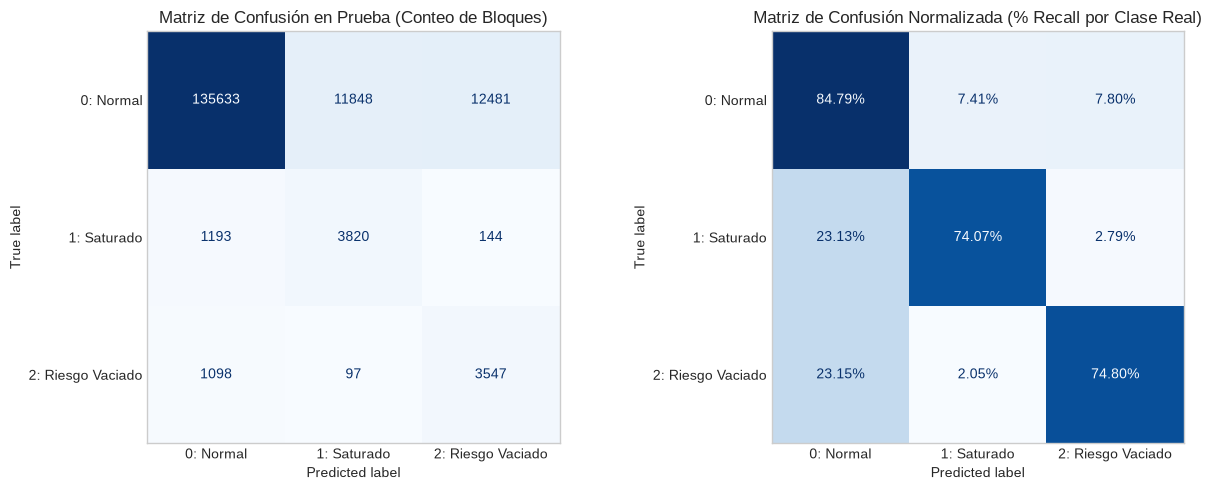

--- Ranking de Importancia de Variables (21 columnas limpias) ---


,Importancia Gini
num_ratios__tasa_saturado_est_hora,0.1972
num_ratios__tasa_vaciado_est_hora,0.1874
num_ratios__ratio_flujo_medio_est_hora,0.1648
num_ratios__ratio_flujo_media_4sem,0.1471
num_yeo_robust__ratio_llegadas_cap_lag1,0.0412
cat_ohe__estado_semana_anterior_1.0,0.0341
cat_ohe__estado_semana_anterior_2.0,0.0320
num_yeo_robust__ratio_acumulado_hoy_cap_lag1,0.0291
num_ratios__longitud,0.0269
num_ratios__latitud,0.0259


In [7]:
nombres_clases = ["0: Normal", "1: Saturado", "2: Riesgo Vaciado"]

pred_val = pipeline_rf.predict(X_val)
pred_test = pipeline_rf.predict(X_test)

print("=====================================================================")
print("             REPORTE DE CLASIFICACIÓN - VALIDACIÓN                   ")
print("=====================================================================")
print(classification_report(y_val, pred_val, target_names=nombres_clases, digits=4))

print("=====================================================================")
print("               REPORTE DE CLASIFICACIÓN - PRUEBA (TEST)              ")
print("=====================================================================")
print(classification_report(y_test, pred_test, target_names=nombres_clases, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_abs = confusion_matrix(y_test, pred_test)
disp_abs = ConfusionMatrixDisplay(confusion_matrix=cm_abs, display_labels=nombres_clases)
disp_abs.plot(cmap="Blues", ax=axes[0], values_format="d", colorbar=False)
axes[0].set_title("Matriz de Confusión en Prueba (Conteo de Bloques)")
axes[0].grid(False)

cm_norm = confusion_matrix(y_test, pred_test, normalize="true")
disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=nombres_clases)
disp_norm.plot(cmap="Blues", ax=axes[1], values_format=".2%", colorbar=False)
axes[1].set_title("Matriz de Confusión Normalizada (% Recall por Clase Real)")
axes[1].grid(False)

plt.show()

importancias = pd.Series(
    pipeline_rf.named_steps["clasificador"].feature_importances_,
    index=nombres_columnas_salida
).sort_values(ascending=False)

print("--- Ranking de Importancia de Variables (21 columnas limpias) ---")
display(importancias.to_frame(name="Importancia Gini").round(4))